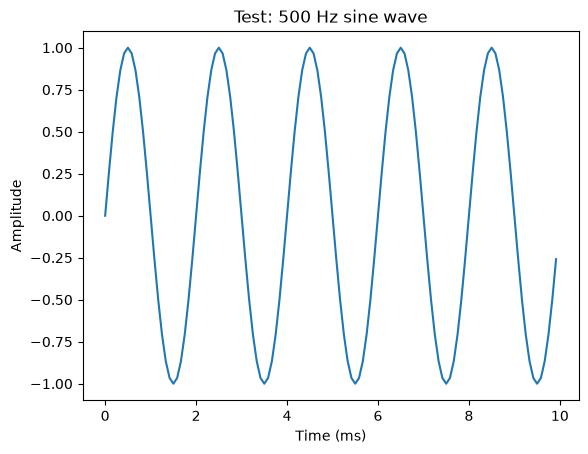

In [9]:
import numpy as np
import matplotlib.pyplot as plt

fs = 12000                      # sampling rate: 12,000 samples per second
t = np.arange(0, 0.01, 1 / fs)  # 10 ms of time
x = np.sin(2 * np.pi * 500 * t) # a 500 Hz sine wave

plt.plot(t * 1000, x)
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Test: 500 Hz sine wave")
plt.show()

In [1]:
from scipy.io import loadmat
data = loadmat("../data/raw/97.mat")
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


In [2]:
signal = data["X097_DE_time"]
print(signal.shape)

(243938, 1)


In [3]:
print(signal.shape[0] / 12000)


20.328166666666668


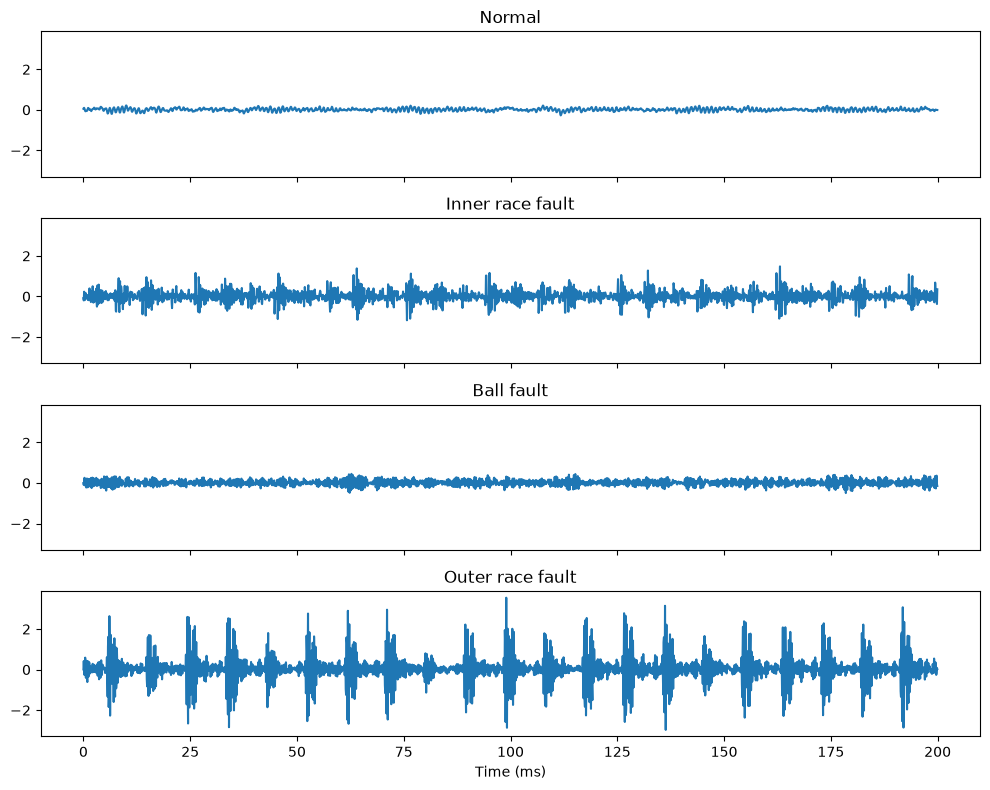

In [4]:
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np

files = {"Normal": "97", "Inner race fault": "105", "Ball fault": "118", "Outer race fault": "130"}

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)
t = np.arange(2400) / 12000 * 1000  # first 0.2 s, in milliseconds

for ax, (label, num) in zip(axes, files.items()):
    data = loadmat(f"../data/raw/{num}.mat")
    key = [k for k in data if k.endswith("DE_time")][0]  # e.g. "X105_DE_time"
    signal = data[key].ravel()
    ax.plot(t, signal[:2400])
    ax.set_title(label)

axes[-1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

In [5]:
import numpy as np

def make_windows(signal, window_size, step):
    windows = []
    for start in range(0, len(signal) - window_size + 1, step):
        windows.append(signal[start: start
                               + window_size
                              ])
    return np.array(windows)

# Test with the toy example
print(make_windows(np.arange(10), window_size=4, step=2))

[[0 1 2 3]
 [2 3 4 5]
 [4 5 6 7]
 [6 7 8 9]]


In [6]:
data = loadmat("../data/raw/97.mat")
signal = data["X097_DE_time"].ravel()

windows = make_windows(signal, window_size=2048, step=2048)
print(windows.shape)

(119, 2048)


In [7]:
split = int(len(signal) * 0.8)   # index where the last 20% starts

train_part = signal[:split]
test_part  = signal[split:]    

train_windows = make_windows(train_part, window_size=2048, step=2048)
test_windows  = make_windows(test_part,  window_size=2048, step=2048)

print("train:", train_windows.shape)
print("test: ", test_windows.shape)

train: (95, 2048)
test:  (23, 2048)


In [8]:
files = {"97": 0, "105": 1, "118": 2, "130": 3}   # file number -> class label

X_train, y_train, X_test, y_test = [], [], [], []

for num, label in files.items():
    data = loadmat(f"../data/raw/{num}.mat")
    key = [k for k in data if k.endswith("DE_time")][0]
    signal = data[key].ravel()

    # 1) split FIRST (no leakage)
    split = int(len(signal) * 0.8)
    train_part = signal[:split]
    test_part  = signal[split:]

    # 2) THEN window each part separately
    tr = make_windows(train_part, window_size=2048, step=2048)
    te = make_windows(test_part,  window_size=2048, step=2048)

    # 3) store windows + a label for each window
    X_train.append(tr); y_train.append(np.full(len(tr), label))
    X_test.append(te);  y_test.append(np.full(len(te), label))

# glue the 4 lists into single arrays
X_train = np.concatenate(X_train); y_train = np.concatenate(y_train)
X_test  = np.concatenate(X_test);  y_test  = np.concatenate(y_test)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)
print("Windows per class (train):", np.bincount(y_train))

X_train: (236, 2048) y_train: (236,)
X_test:  (56, 2048) y_test:  (56,)
Windows per class (train): [95 47 47 47]


In [10]:
from scipy.stats import kurtosis

def rms(x):
    return np.sqrt(np.mean(x ** 2))

class_names = ["Normal", "Inner race", "Ball", "Outer race"]

for label, name in enumerate(class_names):
    w = X_train[y_train == label]                 # all train windows of this class
    r = np.mean([rms(x) for x in w])              # average RMS
    k = np.mean([kurtosis(x) for x in w])         # average kurtosis
    print(f"{name:12s}  RMS = {r:.3f}   kurtosis = {k:.2f}")

Normal        RMS = 0.074   kurtosis = -0.24
Inner race    RMS = 0.291   kurtosis = 2.36
Ball          RMS = 0.138   kurtosis = -0.06
Outer race    RMS = 0.672   kurtosis = 4.60


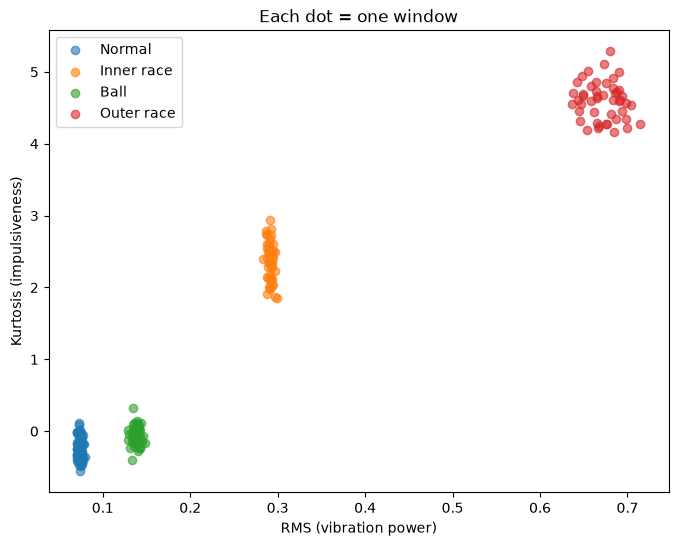

In [11]:
plt.figure(figsize=(8, 6))
for label, name in enumerate(class_names):
    w = X_train[y_train == label]
    r = [rms(x) for x in w]
    k = [kurtosis(x) for x in w]
    plt.scatter(r, k, label=name, alpha=0.6)

plt.xlabel("RMS (vibration power)")
plt.ylabel("Kurtosis (impulsiveness)")
plt.title("Each dot = one window")
plt.legend()
plt.show()

In [12]:
def extract_features(windows):
    feats = []
    for w in windows:
        r = rms(w)
        peak = np.max(np.abs(w))
        feats.append([r, kurtosis(w), peak, peak / r])
    return np.array(feats)

feature_names = ["rms", "kurtosis", "peak", "crest_factor"]

F_train = extract_features(X_train)
F_test  = extract_features(X_test)
print(F_train.shape, F_test.shape)

(236, 4) (56, 4)


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(F_train, y_train)          # learn the boundaries from train windows
pred = rf.predict(F_test)         # predict test windows it has never seen

print(classification_report(y_test, pred, target_names=class_names))

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        23
  Inner race       1.00      1.00      1.00        11
        Ball       1.00      1.00      1.00        11
  Outer race       1.00      1.00      1.00        11

    accuracy                           1.00        56
   macro avg       1.00      1.00      1.00        56
weighted avg       1.00      1.00      1.00        56



In [14]:
# load -> {file number: class label}
FILES = {
    0: {"97": 0, "105": 1, "118": 2, "130": 3},
    1: {"98": 0, "106": 1, "119": 2, "131": 3},
    2: {"99": 0, "107": 1, "120": 2, "132": 3},
    3: {"100": 0, "108": 1, "121": 2, "133": 3},
}

def load_windows(file_map, window_size=2048):
    X, y = [], []
    for num, label in file_map.items():
        data = loadmat(f"../data/raw/{num}.mat")
        signal = data[f"X{num.zfill(3)}_DE_time"].ravel()   # e.g. "X097_DE_time"
        w = make_windows(signal, window_size, window_size)
        X.append(w); y.append(np.full(len(w), label))
    return np.concatenate(X), np.concatenate(y)

# Train on 0 hp only
X_tr, y_tr = load_windows(FILES[0])
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(extract_features(X_tr), y_tr)

# Test on each unseen load
for load in [1, 2, 3]:
    X_te, y_te = load_windows(FILES[load])
    pred = rf.predict(extract_features(X_te))
    acc = (pred == y_te).mean()
    print(f"Train 0 hp -> Test {load} hp: accuracy = {acc:.3f}")

Train 0 hp -> Test 1 hp: accuracy = 1.000
Train 0 hp -> Test 2 hp: accuracy = 1.000
Train 0 hp -> Test 3 hp: accuracy = 1.000


In [15]:
from sklearn.metrics import confusion_matrix
from bearing_fault_detection.cwru import CATALOG, CLASS_NAMES, DATA_DIR

def load_signal(num):
    data = loadmat(DATA_DIR / f"{num}.mat")
    key = f"X{num:03d}_DE_time"
    if key not in data:  # a few CWRU files use a different variable name
        key = [k for k in data if k.endswith("DE_time")][0]
    return data[key].ravel()

def win(sig):
    return make_windows(sig, 2048, 2048)

TEST_SIZE = 0.014
X_tr, y_tr, X_te, y_te = [], [], [], []

for num, (label, size, load) in CATALOG.items():
    sig = load_signal(num)
    if label == 0:                        # Normal: only one healthy bearing -> time split
        split = int(len(sig) * 0.8)
        parts = [(sig[:split], X_tr, y_tr), (sig[split:], X_te, y_te)]
    elif size == TEST_SIZE:               # unseen fault bearings -> test
        parts = [(sig, X_te, y_te)]
    else:                                 # other fault sizes -> train
        parts = [(sig, X_tr, y_tr)]
    for s, X, y in parts:
        w = win(s)
        X.append(w); y.append(np.full(len(w), label))

X_tr, y_tr = np.concatenate(X_tr), np.concatenate(y_tr)
X_te, y_te = np.concatenate(X_te), np.concatenate(y_te)
print("train windows per class:", np.bincount(y_tr))
print("test windows per class: ", np.bincount(y_te))

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(extract_features(X_tr), y_tr)
pred = rf.predict(extract_features(X_te))

print(classification_report(y_te, pred, target_names=CLASS_NAMES))
print(confusion_matrix(y_te, pred))

train windows per class: [662 473 472 472]
test windows per class:  [164 236 236 236]
              precision    recall  f1-score   support

      Normal       0.83      1.00      0.91       164
  Inner race       0.00      0.00      0.00       236
        Ball       0.33      0.93      0.48       236
  Outer race       0.00      0.00      0.00       236

    accuracy                           0.44       872
   macro avg       0.29      0.48      0.35       872
weighted avg       0.24      0.44      0.30       872

[[164   0   0   0]
 [  0   0 236   0]
 [ 16   0 220   0]
 [ 17   0 219   0]]


/Users/batu/projects/bearing-fault-detection/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/batu/projects/bearing-fault-detection/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/batu/projects/bearing-fault-detection/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

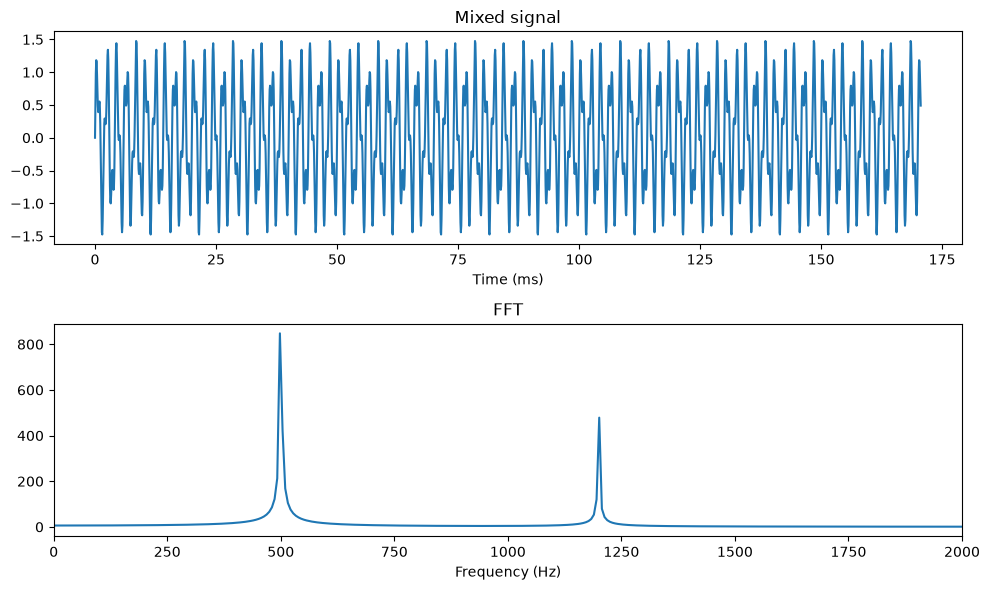

In [16]:
fs = 12000
t = np.arange(2048) / fs
mix = np.sin(2 * np.pi * 500 * t) + 0.5 * np.sin(2 * np.pi * 1200 * t)   # 500 Hz + weaker 1200 Hz

spectrum = np.abs(np.fft.rfft(mix))          # strength of each frequency
freqs = np.fft.rfftfreq(len(mix), d=1 / fs)  # which frequency each value belongs to

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
axes[0].plot(t * 1000, mix); axes[0].set_xlabel("Time (ms)"); axes[0].set_title("Mixed signal")
axes[1].plot(freqs, spectrum); axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_title("FFT")
axes[1].set_xlim(0, 2000)
plt.tight_layout(); plt.show()

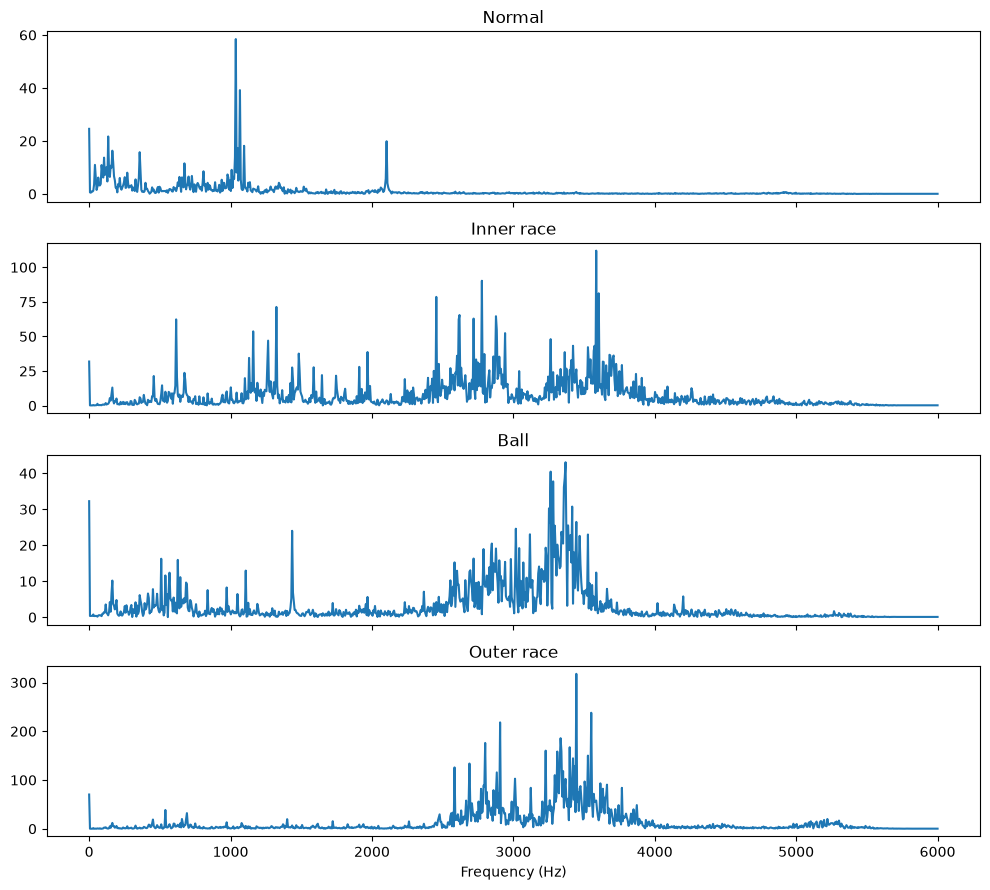

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, (num, name) in zip(axes, [(97, "Normal"), (105, "Inner race"), (118, "Ball"), (130, "Outer race")]):
    w = load_signal(num)[:2048]
    ax.plot(np.fft.rfftfreq(2048, 1 / fs), np.abs(np.fft.rfft(w)))
    ax.set_title(name)
axes[-1].set_xlabel("Frequency (Hz)")
plt.tight_layout(); plt.show()

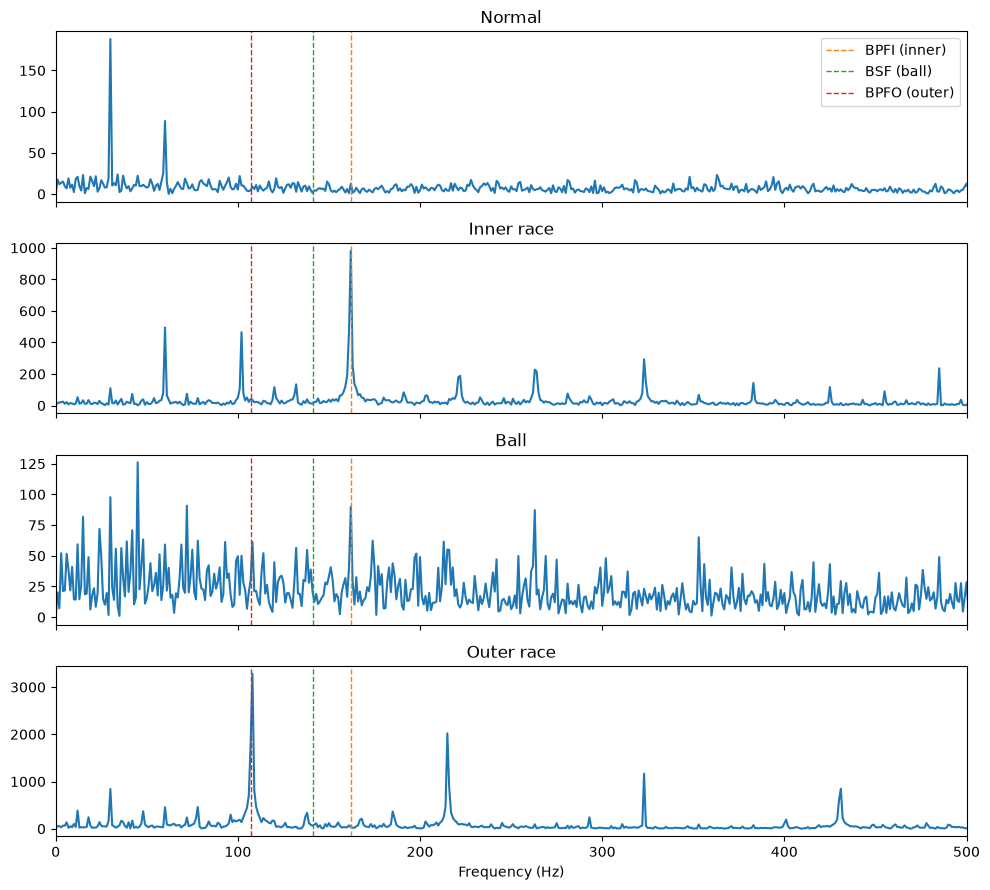

In [18]:
from scipy.signal import hilbert

# Expected fault frequencies for this bearing (SKF 6205) at 1797 rpm
fr = 1797 / 60                      # shaft rotation: ~30 Hz
expected = {"BPFI (inner)": 5.4152 * fr, "BSF (ball)": 4.7135 * fr, "BPFO (outer)": 3.5848 * fr}

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, (num, name) in zip(axes, [(97, "Normal"), (105, "Inner race"), (118, "Ball"), (130, "Outer race")]):
    x = load_signal(num)[:12000]                 # 1 second -> 1 Hz resolution
    env = np.abs(hilbert(x - x.mean()))          # envelope = "rhythm" of the impacts
    env -= env.mean()
    ax.plot(np.fft.rfftfreq(len(env), 1 / fs), np.abs(np.fft.rfft(env)))
    for (lbl, f), c in zip(expected.items(), ["tab:orange", "tab:green", "tab:red"]):
        ax.axvline(f, color=c, ls="--", lw=1, label=lbl)
    ax.set_title(name)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, 500)
plt.tight_layout(); plt.show()

In [19]:
from sklearn.metrics import f1_score

RPM = {0: 1797, 1: 1772, 2: 1750, 3: 1730}
ORDERS = {"bpfi": 5.4152, "bsf": 4.7135, "bpfo": 3.5848}   # fault frequency / shaft frequency

def envelope_features(window, rpm, fs=12000):
    env = np.abs(hilbert(window - window.mean()))
    env -= env.mean()
    spec = np.abs(np.fft.rfft(env))
    freqs = np.fft.rfftfreq(len(env), 1 / fs)
    ref = np.median(spec) + 1e-12            # overall level -> makes features amplitude-independent
    feats = []
    for order in ORDERS.values():
        for h in (1, 2):                     # fundamental + 2nd harmonic
            f0 = h * order * rpm / 60
            band = (freqs > f0 - 6) & (freqs < f0 + 6)
            feats.append(spec[band].max() / ref)
    return feats

# Rebuild the fault-size split, this time also remembering the rpm of each window
X_tr, y_tr, r_tr, X_te, y_te, r_te = [], [], [], [], [], []
for num, (label, size, load) in CATALOG.items():
    sig, rpm = load_signal(num), RPM[load]
    if label == 0:
        split = int(len(sig) * 0.8)
        parts = [(sig[:split], X_tr, y_tr, r_tr), (sig[split:], X_te, y_te, r_te)]
    elif size == TEST_SIZE:
        parts = [(sig, X_te, y_te, r_te)]
    else:
        parts = [(sig, X_tr, y_tr, r_tr)]
    for s, X, y, r in parts:
        w = win(s)
        X.append(w); y.append(np.full(len(w), label)); r.append(np.full(len(w), rpm))

X_tr, y_tr, r_tr = map(np.concatenate, (X_tr, y_tr, r_tr))
X_te, y_te, r_te = map(np.concatenate, (X_te, y_te, r_te))

E_tr = np.array([envelope_features(w, r) for w, r in zip(X_tr, r_tr)])
E_te = np.array([envelope_features(w, r) for w, r in zip(X_te, r_te)])
T_tr, T_te = extract_features(X_tr), extract_features(X_te)

experiments = {
    "time features (old)": (T_tr, T_te),
    "envelope features":   (E_tr, E_te),
    "time + envelope":     (np.hstack([T_tr, E_tr]), np.hstack([T_te, E_te])),
}
for name, (F_tr, F_te) in experiments.items():
    rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(F_tr, y_tr)
    pred = rf.predict(F_te)
    print(f"\n=== {name} ===  accuracy={np.mean(pred == y_te):.3f}  macro-F1={f1_score(y_te, pred, average='macro'):.3f}")
    print(confusion_matrix(y_te, pred))


=== time features (old) ===  accuracy=0.440  macro-F1=0.348
[[164   0   0   0]
 [  0   0 236   0]
 [ 16   0 220   0]
 [ 17   0 219   0]]

=== envelope features ===  accuracy=0.453  macro-F1=0.412
[[147   0  17   0]
 [  0 131 105   0]
 [118   0 117   1]
 [232   0   4   0]]

=== time + envelope ===  accuracy=0.532  macro-F1=0.485
[[164   0   0   0]
 [  0  79 157   0]
 [ 14   0 221   1]
 [ 20   0 216   0]]


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
bpfo = 3.5848 * 1797 / 60
for ax, (num, name) in zip(axes, [(130, 'OR 0.007"'), (197, 'OR 0.014"  (test)'), (234, 'OR 0.021"')]):
    x = load_signal(num)[:12000]
    env = np.abs(hilbert(x - x.mean())); env -= env.mean()
    ax.plot(np.fft.rfftfreq(len(env), 1 / fs), np.abs(np.fft.rfft(env)))
    for h in (1, 2, 3):
        ax.axvline(h * bpfo, color="tab:red", ls="--", lw=1)
    ax.set_title(name)
axes[-1].set_xlabel("Frequency (Hz)"); axes[-1].set_xlim(0, 500)
plt.tight_layout(); plt.show()